## Who Worked On This Part?
Aarya Ray Chaudhuri: trained and tuned the support vector machine (RBF kernel), the fourth model, and compared what it learns with Azaam's random forest.

# Mushroom: support vector machine

Azaam tried three models: logistic regression (a straight line through the data), a random forest (hundreds of independent trees) and gradient boosting (trees built one after the other). Two of the three are tree models. This notebook adds a model that works in a completely different way: a **support vector machine (SVM) with an RBF kernel**.

**How an SVM works:**
- A linear SVM looks for the straight boundary between edible and poisonous with the widest possible empty band around it, the **margin**. Only the mushrooms on or inside that band decide where the boundary goes: the **support vectors**. All other mushrooms could be removed without changing the model.
- Real data is rarely split by a straight line. The **kernel trick** compares mushrooms with a similarity function instead. The RBF kernel calls two mushrooms similar when they are close together, so the boundary can bend around groups of mushrooms. It works as if the data were moved to a space with many more dimensions, without ever computing that space.
- Two settings: `C` is how much a mushroom on the wrong side of the margin costs (small `C` = a wide, tolerant margin, big `C` = bend the boundary for every single mushroom). `gamma` is how far the influence of one mushroom reaches (small = a smooth boundary, big = a tight bubble around every training mushroom, which is memorising).

**Why this model, and what we want to learn from it:**
1. It takes exactly the same input as Azaam's logistic regression (one-hot categories, log1p and scaled numbers). The only difference is the kernel, so the gap between the two shows what a curved boundary is worth on this data.
2. Its boundary is smooth and built from distances between mushrooms, while trees cut the data with yes/no questions on one column at a time. If the SVM gets as far as the trees, there's nothing special about trees here. If it stays behind, something in this data suits trees.
3. If a model built this differently also stops at about the same AUC as the forest, that is more evidence that the limit is the data (noisy labels), not the choice of model.

It also suits the data: a few thousand rows and 64 one-hot columns is a comfortable size for an SVM, and `C` decides how hard it tries to fit mislabelled mushrooms. PyCaret only tried the *linear* SVM (AUC 0.63), not the RBF kernel.

We use scikit-learn 1.6.1 here, the version Azaam saved his models with, so all models can be loaded side by side in the compare notebook.

## Load the split
Same train and validation files as Azaam's model notebooks, so all models learn from and are scored on exactly the same rows. The test file stays untouched until the compare notebook.

In [1]:
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# walk up from where the notebook runs to the repo root, so the data path works on every machine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Mushroom' / 'datasets').is_dir())
DATA = ROOT / 'Mushroom' / 'datasets'

train_df = pd.read_csv(DATA / 'train.csv')
val_df = pd.read_csv(DATA / 'val.csv')

X_train, y_train = train_df.drop(columns='is_poisonous'), train_df['is_poisonous']
X_val, y_val = val_df.drop(columns='is_poisonous'), val_df['is_poisonous']

num_cols = ['cap_diameter_cm', 'stem_height_cm', 'stem_width_mm']
cat_cols = [c for c in X_train.columns if c not in num_cols]

print('scikit-learn', sklearn.__version__)
X_train.shape, X_val.shape

scikit-learn 1.6.1


((3500, 10), (750, 10))

## How we score a model
The same `evaluate()` as in Azaam's notebooks, plus PR-AUC from the compare notebook: how precise the model stays while it catches more and more poisonous mushrooms. We also use the same 5 cross-validation folds as Azaam (`StratifiedKFold` with `random_state=42`), so cross-validation scores can be compared fold by fold.

In [2]:
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score, f1_score, accuracy_score
from sklearn.model_selection import StratifiedKFold

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        'roc_auc': roc_auc_score(y_true, proba),
        'pr_auc': average_precision_score(y_true, proba),
        'recall': recall_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred),
        'accuracy': accuracy_score(y_true, pred),
    }

# the same 5 folds as in Azaam's notebooks
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## The pipeline
An SVM measures distances between mushrooms, so every column has to be on a comparable scale, otherwise stem width (in mm) would outweigh everything else. So we prepare the data exactly like Azaam's logistic regression:
- **categories**: one-hot encoded, every value becomes its own 0/1 column
- **numbers**: `log1p` (the sizes are right-skewed), then `StandardScaler` (mean 0, standard deviation 1)

The model starts with the default settings: RBF kernel, `C=1` and `gamma='scale'`, where scikit-learn picks gamma from the spread of the prepared data. We print what that value is for our data, so we know where to search later.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.svm import SVC

prep = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), num_cols),
])

svm = Pipeline([
    ('prep', prep),
    ('svm', SVC(kernel='rbf', random_state=42)),
])

# what gamma='scale' works out to: 1 / (number of columns x variance of the prepared data)
X_ready = prep.fit_transform(X_train).toarray()
print('prepared data:', X_ready.shape)
print("gamma='scale' =", round(1 / (X_ready.shape[1] * X_ready.var()), 3))

prepared data: (3500, 64)
gamma='scale' = 0.108


The prepared data has 64 columns: 61 one-hot columns for the 7 categories (each with its own `missing` value) and the 3 scaled measurements. For this data the default `gamma` works out to 0.108.

## Step 1: which kernel?
Before tuning anything we check that the RBF kernel is the right choice. We compare the three common kernels with their default settings on the 5 folds:
- `linear`: a straight boundary, the same idea as logistic regression
- `poly`: a curved boundary built from products of features (degree 3)
- `rbf`: a boundary that bends around groups of nearby mushrooms

`cross_val_score` trains the pipeline 5 times, each time on 4 folds, and scores the 5th. For an SVM the AUC is computed from its distance to the boundary (`decision_function`), which ranks the mushrooms just like a probability would.

In [4]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

kernels = {}
for kernel in ['linear', 'poly', 'rbf']:
    model = clone(svm).set_params(svm__kernel=kernel)
    kernels[kernel] = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

pd.DataFrame({k: {'mean cv AUC': s.mean(), 'std': s.std()} for k, s in kernels.items()}).T.round(3)

,mean cv AUC,std
linear,0.688,0.018
poly,0.794,0.012
rbf,0.793,0.012


### What this tells us
The straight boundary (`linear`, 0.688) is as weak as Azaam's logistic regression (cross-validated 0.70): the same input and a straight line give the same result, whichever model draws the line. Both curved kernels jump to about 0.79 (poly 0.794, rbf 0.793). So what logistic regression misses is that the boundary has to bend: combinations of features carry the signal, not single features on their own.

`poly` and `rbf` are equal here: the difference of 0.001 is far below the spread between folds (0.012). We continue with RBF because it has two settings to tune (`C` and `gamma`), where `poly` has four (`degree` and `coef0` as well), and it's scikit-learn's default kernel.

## Step 2: does the scaling matter?
The slides say an SVM needs scaled inputs. We test it instead of assuming it: the same RBF SVM with three versions of the number columns (the categories stay one-hot):
- `log1p` + scaling (our pipeline)
- scaling only
- the raw numbers in cm and mm

In [5]:
number_preps = {
    'log1p + scaling': make_pipeline(FunctionTransformer(np.log1p), StandardScaler()),
    'scaling only': StandardScaler(),
    'raw numbers': 'passthrough',
}
scaling = {}
for name, num_prep in number_preps.items():
    model = clone(svm).set_params(prep__num=num_prep)
    scaling[name] = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

pd.DataFrame({k: {'mean cv AUC': s.mean(), 'std': s.std()} for k, s in scaling.items()}).T.round(3)

,mean cv AUC,std
log1p + scaling,0.793,0.012
scaling only,0.789,0.016
raw numbers,0.696,0.012


### What this tells us
Scaling is essential: with the raw measurements the AUC falls from 0.793 to 0.696, back to the level of a straight line. The measurements are in the tens of cm and mm while the one-hot columns are 0 or 1, so the measurements dominate every distance and the categories hardly count anymore.

`log1p` on top of the scaling hardly matters for the SVM (0.793 against 0.789, well within the spread of 0.012 to 0.016). It doesn't hurt either, so we keep exactly the preparation of logistic regression, which keeps the comparison between the two clean.

## Step 3: tune C and gamma
`GridSearchCV` tries every combination of 7 values of `C` and 6 values of `gamma`: 42 combinations, each on the 5 folds, so 210 SVMs. It keeps the best by AUC. Validation is not used for choosing.

The values go up in steps of about ×3, because for these two settings the order of magnitude matters, not the exact number. The grid goes well below and above the default `gamma` printed above.

In [6]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    svm,
    param_grid={
        'svm__C': [0.1, 0.3, 1, 3, 10, 30, 100],
        'svm__gamma': [0.003, 0.01, 0.03, 0.1, 0.3, 1],
    },
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
)
grid.fit(X_train, y_train)

results = pd.DataFrame(grid.cv_results_)
print('best settings:', grid.best_params_)
results.sort_values('rank_test_score')[['param_svm__C', 'param_svm__gamma', 'mean_test_score', 'std_test_score']].head(8).round(3)

best settings: {'svm__C': 1, 'svm__gamma': 0.3}


,param_svm__C,param_svm__gamma,mean_test_score,std_test_score
16,1.0,0.30,0.807,0.007
27,10.0,0.10,0.804,0.007
21,3.0,0.10,0.804,0.011
38,100.0,0.03,0.802,0.010
22,3.0,0.30,0.799,0.007
32,30.0,0.03,0.799,0.013
10,0.3,0.30,0.791,0.015
15,1.0,0.10,0.791,0.013


The heatmap shows all 42 combinations at once: rows are `C`, columns are `gamma`, and the number in each square is the mean cross-validated AUC.

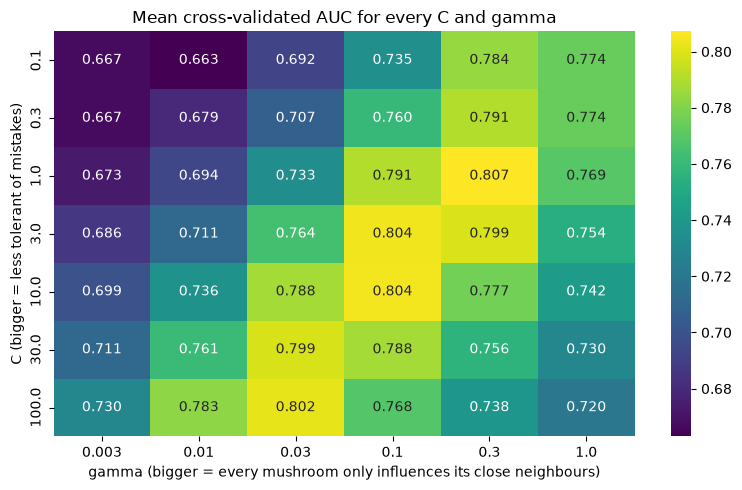

In [7]:
heat = results.pivot(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='viridis')
plt.xlabel('gamma (bigger = every mushroom only influences its close neighbours)')
plt.ylabel('C (bigger = less tolerant of mistakes)')
plt.title('Mean cross-validated AUC for every C and gamma')
plt.tight_layout()
plt.show()

### What this tells us
The best combination is `C=1`, `gamma=0.3`, with cross-validated AUC **0.807 ± 0.007**. It sits inside the grid, not on an edge, so the grid was wide enough.

The heatmap shows a diagonal ridge: a bigger `C` goes with a smaller `gamma` (`C=1` with `gamma=0.3`, `C=3` or `10` with `0.1`, `C=100` with `0.03` all score 0.802 to 0.807). Both settings control the same thing, how closely the boundary follows single mushrooms, so one can make up for the other. Along the ridge the scores differ by less than the spread between folds.

Off the ridge it goes wrong in two ways:
- **too smooth** (small `C` and small `gamma`, top left): 0.66 to 0.69, a nearly straight boundary, as weak as the linear kernel
- **too wiggly** (`gamma=1`, right column): 0.72 to 0.77, every mushroom gets its own small bubble, which means memorising the noisy labels

## Step 4: is the tuned SVM really better than the default?
Like Azaam did for gradient boosting, we compare the default and the tuned SVM on the **same 5 folds**, fold by fold. A gain only counts if it is bigger than the spread between folds and shows up in most folds. The default scores come from Step 1 (same model, same folds), the tuned ones from the grid search.

In [8]:
best = grid.best_index_
folds = pd.DataFrame({
    'default': kernels['rbf'],
    'tuned': [results.loc[best, f'split{i}_test_score'] for i in range(5)],
}, index=[f'fold {i + 1}' for i in range(5)])
folds['difference'] = folds['tuned'] - folds['default']
print('tuned better in', (folds['difference'] > 0).sum(), 'of 5 folds')
folds.round(3)

tuned better in 5 of 5 folds


,default,tuned,difference
fold 1,0.778,0.797,0.019
fold 2,0.784,0.801,0.016
fold 3,0.809,0.817,0.008
fold 4,0.807,0.811,0.004
fold 5,0.787,0.811,0.024


### What this tells us
Tuning really helps the SVM: on the same folds the tuned SVM is better in **all 5 folds**, by 0.004 to 0.024 (0.014 on average). That is different from Azaam's gradient boosting and from our SageMaker forest, where tuning stayed within the noise between folds. The heatmap shows why: the default (`C=1`, `gamma` 0.108) sits just below the ridge (0.791 at `gamma=0.1`), and tuning moves it onto it.

## Step 5: class weights
Only 38% of the training mushrooms are poisonous. Azaam showed for logistic regression that `class_weight='balanced'` moves the predictions towards "poisonous" but doesn't change the AUC. We check if that also holds for the SVM, with the tuned settings and the same folds.

In [9]:
tuned = grid.best_estimator_
balanced = clone(tuned).set_params(svm__class_weight='balanced')
weights = pd.DataFrame({
    'no weights': folds['tuned'].to_numpy(),
    'balanced': cross_val_score(balanced, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1),
}, index=folds.index)
weights.agg(['mean', 'std']).round(3)

,no weights,balanced
mean,0.807,0.804
std,0.008,0.007


Balancing the classes doesn't help the SVM either: 0.804 against 0.807, a difference far below the spread between folds (0.007). As with logistic regression it would only shift the predictions, and we set the threshold for 90% recall ourselves in the compare notebook anyway. So the final SVM has no class weights.

## Step 6: from distance to probability
An SVM doesn't give a chance of being poisonous, only a distance to the boundary. To choose a threshold for 90% recall, and to compare with the other models, we need a chance between 0 and 1. `probability=True` adds **Platt scaling**: during `fit` the SVM is trained 5 more times on parts of the training data, and a logistic curve is fitted that turns the distance into a chance. That makes training about 6 times slower, but it doesn't change the order of the mushrooms, so the AUC should stay the same. We check that, and compare train with validation to see if the tuned SVM overfits.

In [10]:
import time

svm_tuned = clone(tuned).set_params(svm__probability=True)
start = time.time()
svm_tuned.fit(X_train, y_train)
print('training time:', round(time.time() - start, 1), 's')

val_proba = svm_tuned.predict_proba(X_val)[:, 1]
print('validation AUC from the distance:   ', round(roc_auc_score(y_val, svm_tuned.decision_function(X_val)), 4))
print('validation AUC from the probability:', round(roc_auc_score(y_val, val_proba), 4))

svm_default = clone(svm).set_params(svm__probability=True).fit(X_train, y_train)
pd.DataFrame({
    'svm default (val)': evaluate(y_val, svm_default.predict_proba(X_val)[:, 1]),
    'svm tuned (train)': evaluate(y_train, svm_tuned.predict_proba(X_train)[:, 1]),
    'svm tuned (val)': evaluate(y_val, val_proba),
}).T.round(3)

training time: 2.4 s
validation AUC from the distance:    0.8213
validation AUC from the probability: 0.8213


,roc_auc,pr_auc,recall,precision,f1,accuracy
svm default (val),0.799,0.769,0.542,0.824,0.654,0.783
svm tuned (train),0.936,0.917,0.737,0.910,0.814,0.873
svm tuned (val),0.821,0.763,0.599,0.762,0.671,0.777


### What this tells us
- Platt scaling didn't change the ranking: the validation AUC is 0.8213 from the distance and from the probability.
- On validation the tuned SVM gets **AUC 0.821** (the default 0.799). That's above its cross-validated 0.807, the same way Azaam's forest (0.852 against 0.832) and boosting (0.829 against 0.822) scored higher on validation than in cross-validation: this validation set is a bit easier than the average fold.
- Train AUC 0.936 against 0.821 on validation: the SVM fits its training rows better than new ones, but far less extremely than the tree models (Azaam's forest 1.000 against 0.852, his tuned boosting 0.997 against 0.829). With `gamma=0.3` every mushroom still influences a wide neighbourhood, so the SVM can't memorise single rows the way a fully grown tree can.
- At threshold 0.5 it catches 60% of the poisonous mushrooms (recall 0.599) with precision 0.762.

The four outcomes on validation at threshold 0.5, like for Azaam's models. We use "probability ≥ 0.5", the same rule as `evaluate()`.

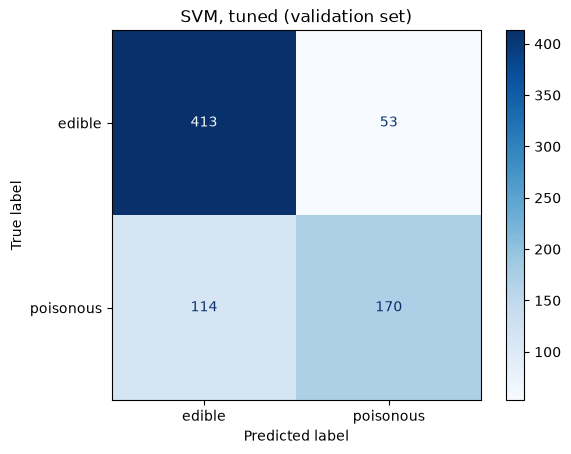

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_val, (val_proba >= 0.5).astype(int), display_labels=['edible', 'poisonous'], cmap='Blues')
plt.title('SVM, tuned (validation set)')
plt.show()

At threshold 0.5 the SVM calls 114 of the 284 poisonous validation mushrooms edible, and 53 edible ones poisonous. Azaam's tuned forest misses 108 at the same threshold (`3.2MushroomRandomForest.ipynb`). For every model 0.5 is not the threshold we use: the compare notebook picks the one that catches 90% of the poisonous mushrooms.

## Step 7: how many support vectors?
Only the support vectors decide where the boundary goes. If edible and poisonous mushrooms were cleanly separated, only the few mushrooms near the border would be needed. So the share of training mushrooms that end up as support vectors tells us how much the two classes overlap.

In [12]:
fitted = svm_tuned.named_steps['svm']
support = pd.Series(fitted.n_support_, index=['edible', 'poisonous'])
print('support vectors:', support.sum(), 'of', len(X_train), f'training mushrooms ({support.sum() / len(X_train):.0%})')
(support / y_train.value_counts().sort_index().to_numpy()).round(2).rename('share of the class that are support vectors')

support vectors: 2494 of 3500 training mushrooms (71%)


edible       0.63
poisonous    0.85
Name: share of the class that are support vectors, dtype: float64

### What this tells us
2494 of the 3500 training mushrooms (71%) are support vectors: 85% of the poisonous ones and 63% of the edible ones. If the classes were well separated this would be a small group near the border. Here most mushrooms lie on or inside the margin, or on the wrong side of the boundary: edible and poisonous mushrooms overlap a lot in these 10 columns. That fits the weak features we found in the EDA and the flipped labels the assignment warns about.

It also means the model isn't small: every prediction compares the new mushroom with 2494 stored ones.

## Step 8: does the SVM use the same features as the forest?
Permutation importance, exactly as Azaam did for the random forest in `3.2MushroomRandomForest.ipynb`: shuffle one column of the validation set and measure how much the AUC drops, 10 shuffles per column. We compute it for the SVM and, with the same settings, for Azaam's saved forest, so the two can be shown side by side. Loading his forest doesn't change it.

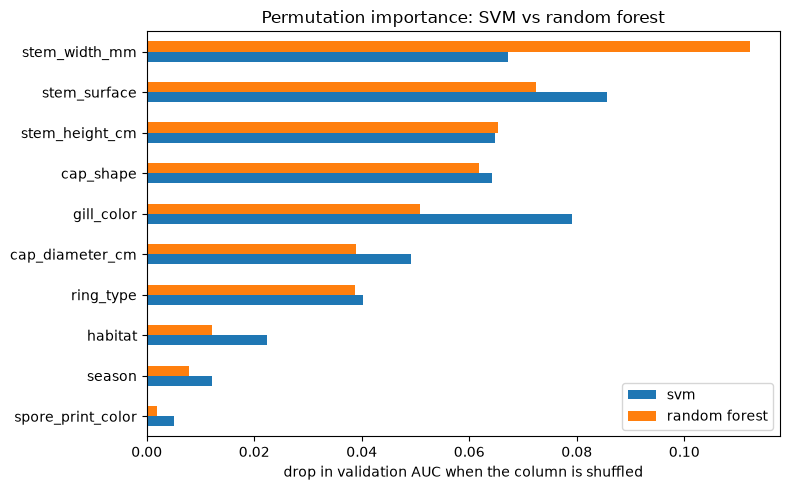

,svm,random forest
stem_surface,0.086,0.072
gill_color,0.079,0.051
stem_width_mm,0.067,0.112
stem_height_cm,0.065,0.065
cap_shape,0.064,0.062
cap_diameter_cm,0.049,0.039
ring_type,0.040,0.039
habitat,0.022,0.012
season,0.012,0.008
spore_print_color,0.005,0.002


In [13]:
import joblib
from sklearn.inspection import permutation_importance

MODELS = ROOT / 'Mushroom' / 'models'
forest = joblib.load(MODELS / 'random_forest.pkl')

importance = pd.DataFrame({
    'svm': permutation_importance(svm_tuned, X_val, y_val, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1).importances_mean,
    'random forest': permutation_importance(forest, X_val, y_val, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1).importances_mean,
}, index=X_val.columns).sort_values('random forest')

importance.plot.barh(figsize=(8, 5))
plt.xlabel('drop in validation AUC when the column is shuffled')
plt.title('Permutation importance: SVM vs random forest')
plt.tight_layout()
plt.show()
importance.sort_values('svm', ascending=False).round(3)

### What this tells us
Both models rely on the same five columns (stem surface, gill color, stem width, stem height, cap shape) and both hardly use habitat, season and spore print color. So two very different architectures found the same signal in the data.

The difference is in how they use it. The forest gets much more out of **stem width** (0.112 against 0.067), the SVM leans more on the categories **gill color** (0.079 against 0.051) and **stem surface** (0.086 against 0.072). A tree can put a sharp cut at any stem width, while for the SVM stem width is one smooth direction among 64. That is a likely reason the forest stays ahead: it gets more out of the measurements.

## Save the model
Like Azaam's models, the whole pipeline (preparation + SVM with probabilities) goes to `models/svm.pkl`, so the compare notebook can load it next to the other three.

In [14]:
joblib.dump(svm_tuned, MODELS / 'svm.pkl', compress=3)  # compress: the support vectors are stored inside the model
print(round((MODELS / 'svm.pkl').stat().st_size / 1e6, 2), 'MB')

0.1 MB


# Story
We added a fourth model that works differently from Azaam's three: an SVM with an RBF kernel, which draws a smooth boundary from distances between mushrooms.

**1. A curved boundary is what logistic regression was missing.** With the same input, a straight boundary scores 0.688 (linear kernel) and a curved one 0.793 before any tuning. So most of the gap between logistic regression and the tree models comes from combinations of features, not from trees as such.

**2. Tuning helps the SVM, unlike the other models.** The best setting (`C=1`, `gamma=0.3`) gets cross-validated AUC 0.807 ± 0.007, better than the default in all 5 folds. The good settings form a diagonal ridge, because `C` and `gamma` can make up for each other.

**3. The SVM stays behind the forest.** Cross-validated 0.807 against 0.832 for Azaam's forest on the same folds, and 0.821 against 0.852 on validation. Both models use the same five columns, but the forest gets more out of stem width, where a tree can make sharp cuts.

**4. The classes overlap a lot.** 71% of the training mushrooms are support vectors. The SVM can't find a clean border, which matches the weak features and noisy labels we found before.

What we tested instead of assumed: the kernel (rbf and poly 0.79, linear 0.69), the scaling (without it 0.696), class weights (no gain, 0.804 against 0.807) and Platt scaling (the AUC stays 0.8213).

**What this means for the compare notebook:** the SVM is saved in `models/svm.pkl` (0.1 MB, scikit-learn 1.6.1). In `4MushroomCompare.ipynb` we put it next to Azaam's three models and our SageMaker forest: on validation, on the same cross-validation folds and once on the test set. We also check if it misses the same poisonous mushrooms as the forest. If a model built this differently misses the same ones, that supports Azaam's conclusion that those mushrooms look edible in every column.